<img src="https://drive.google.com/uc?export=view&id=1Q6vQcIWFPY27isBepABpJ7nroUNKox_Z" width="100%">

# **Extracción de Características**
---

## **0. Integrantes del equipo de trabajo**
---

Nombres completos de los integrantes del equipo de trabajo:


1. Jhon Anderson Bermudez Hurtado
2. Juan Carlos Andrade Unigarro
3. Natalia Patricia Remolina Rodriguez


Durante la tercera fase del proyecto, con el texto ya procesado, nos enfocaremos en identificar las características más relevantes para clasificar correctamente los textos en función de nuestra variable objetivo categórica, `label`. Para ello, utilizaremos y compararemos técnicas de extracción de características para un problema de Procesamiento de Lenguaje Natural (**PLN**), cumpliendo con el cronograma establecido en el diagrama de Gantt para la semana 5.

Además de implementar las representaciones, esta entrega incorpora tres criterios explícitos para justificar la selección final: **adecuación al dominio de noticias económicas**, **capacidad discriminante respecto a la clase** y **eficiencia computacional**. El conjunto `test` se mantiene completamente aislado y no se utiliza para escoger la representación ni sus hiperparámetros.


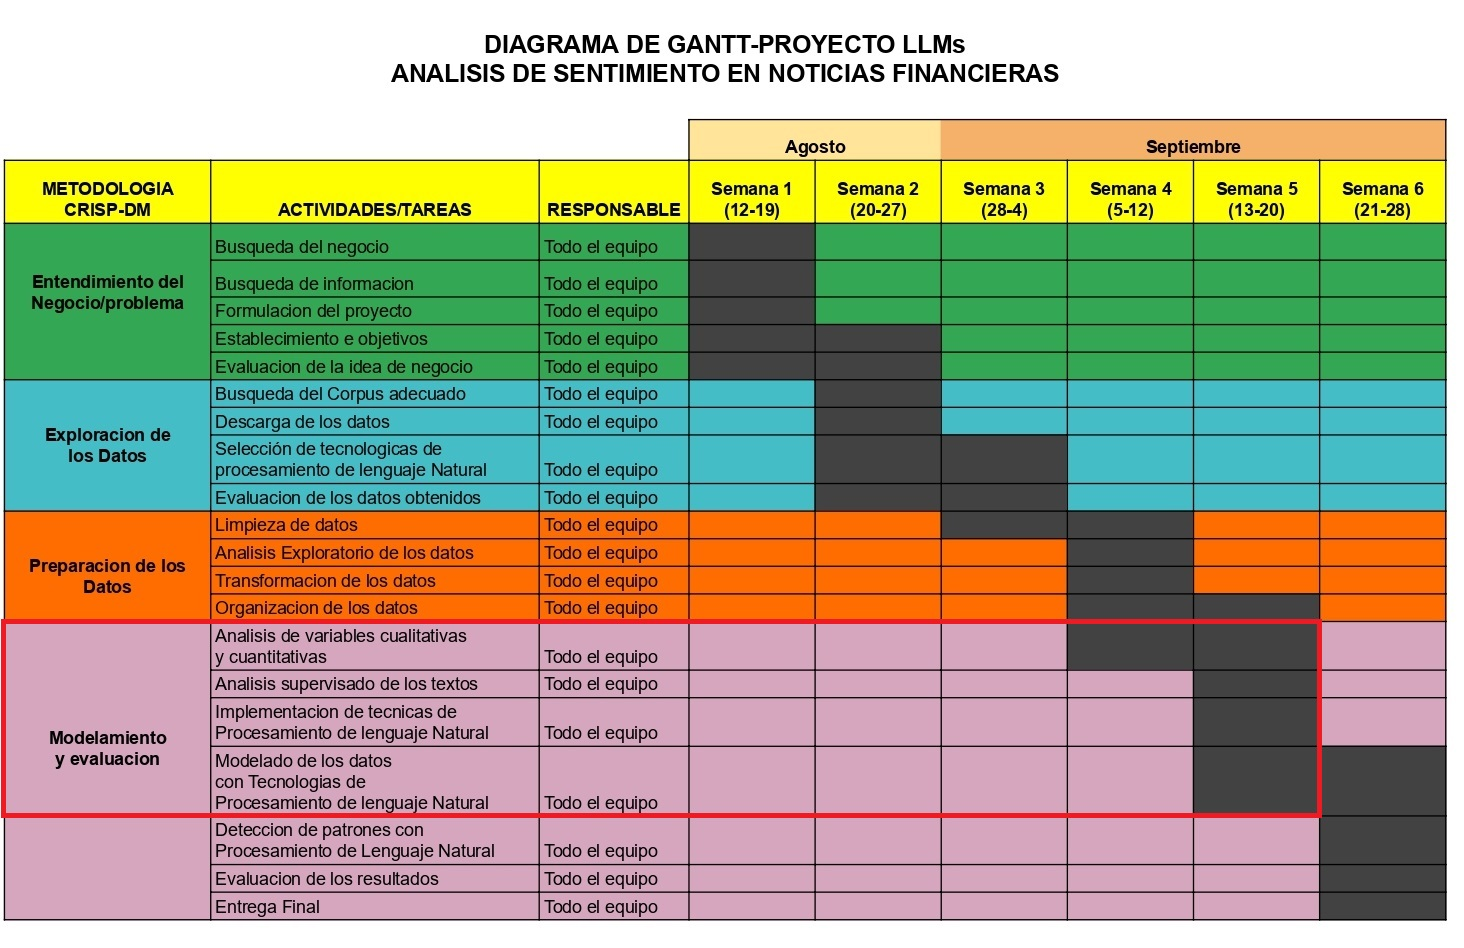

#### Instalamos y cargamos los paquetes necesarios


In [1]:
%%capture
!pip install gensim

In [2]:
# Imports

import os
import time
import pandas as pd
import numpy as np
import sys
from google.colab import drive
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import logging

from gensim.models.doc2vec import Doc2Vec
from gensim.models.word2vec import Word2Vec
from gensim.models.doc2vec import TaggedDocument

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
)
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score



#### **Cargue del conjunto de datos**

En esta etapa se realizará el cargue del conjunto de datos los cuales ya estan procesados como resultado de la fase anterior y estan listos para la fase de modelamiento.
Este dataset esta disponible desde Github por medio de este enlace: https://github.com/JhonAnderson44/financial_sentiment_es_prepared

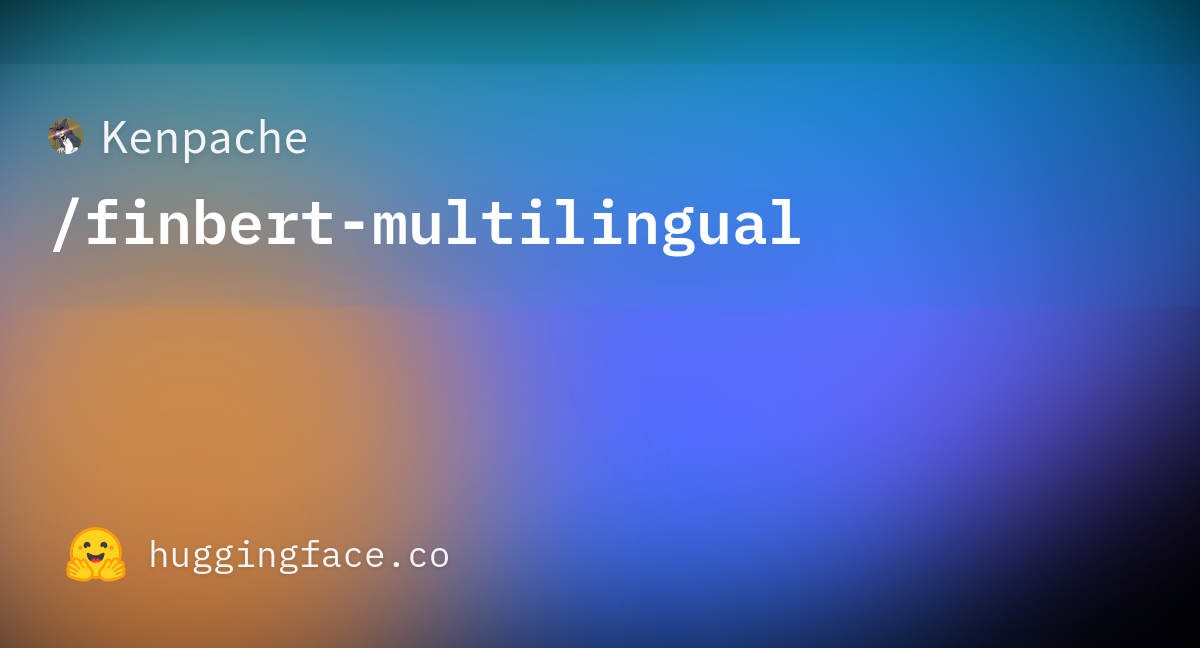

In [3]:
#Cargue de conjunto de datos correcto desde Github
data_path ="https://raw.githubusercontent.com/JhonAnderson44/financial_sentiment_es_prepared/refs/heads/main/financial_sentiment_es_prepared.csv"
data = pd.read_csv(data_path)
data.head()

,sentence_original,sentence_clean,label,source,language,encoding_flag
0,- Isdin abrirá un centro logístico de 22.000 m...,isdin abrir centro logístico num metro bunzl a...,positive,expansion_empresas,es,True
1,MiiN Cosmetics dispara los ingresos y pisa el ...,miin cosmetics disparar ingreso pisa acelerado...,positive,expansion_empresas,es,False
2,La subida del volumen de negocio coincidió con...,subida volumen negocio coincidir apertura num ...,positive,expansion_empresas,es,True
3,La compańía barcelonesa entró el ańo pasado en...,compańía barcelonesa entrar ańo grecia firmar ...,neutral,expansion_empresas,es,True
4,MiiN también abrió en 2025 un centro logístico...,miin abrir num centro logístico num metro cuad...,positive,expansion_empresas,es,True


---

## **Representación Numérica del Texto: Embeddings**

En este análisis, nos centraremos en el texto contenido en la columna `sentence_clean` de nuestro conjunto de datos. El objetivo principal es comprender la necesidad y las diferentes técnicas para representar texto de forma numérica, un paso crucial en el procesamiento del lenguaje natural (NLP) para el aprendizaje automático.

Cuando trabajamos con texto como variable de entrada en modelos de aprendizaje automático, surge una limitación fundamental: las computadoras no "entienden" el texto en su forma natural. Los algoritmos de machine learning operan con datos numéricos, realizando cálculos matemáticos sobre ellos. Por lo tanto, no podemos alimentar directamente los modelos con cadenas de texto.

Para superar esta barrera, necesitamos transformar el texto en una representación numérica que capture su significado semántico y sintáctico, permitiendo que los algoritmos puedan procesarlo y aprender de él. Estas representaciones se conocen comúnmente como *embeddings* (incrustaciones). Un embedding representa una palabra, frase o documento como un vector numérico en un espacio multidimensional. La posición de este vector en el espacio refleja el significado del elemento representado: palabras con significados similares estarán ubicadas cerca unas de otras.

<center>
  <img src="https://drive.google.com/uc?export=view&id=1m9pQizY35Tonc86nG5-Tmhcx8gKWj8yX" width="100%" alt="Tokenización">
</center>

Existen numerosos métodos para obtener estas representaciones; en general se toman en cuneta dos factores para definir alguno de estos, el tamaño de la unidad analizada  y el volumen del conjunto de datos.







### **Tamaño de la unidad:**

Al realizar la codificación de los textos, queremos poder representar estructuras de distintos tamaños, como palabras u oraciones. Una primera forma de determinar el método que podemos usar es definir la estructura que queremos representar.

Dicha estructura debe ser  dividida en unidades que nos permitan entender su composición; estas unidades son llamadas *Tokens*. Si bien, este concepto es utilizado desde entregas pasadas, lo retomaremos como parte del proceso de representación.

<center>
  <img src="https://drive.google.com/uc?export=view&id=1zmkjFtY0YO--9ZOxXHZdubPWUzIGLqOz" width="100%" alt="Tokenización">
</center>

Como se mencionó anteriormente, al identificar el tipo de estructura que buscamos representar numéricamente, podemos empezar a definir el método. A continuación observaremos algunas de las opciones:

*   **Palabras:** Cuando buscamos representar una palabra, podemos encontrar múltiples métodos para ello. Estos pueden ser clasificados entre modelos frecuentistas y profundos. En el caso de métodos frecuentistas, encontramos algunos como la bolsa de palabras y sus variaciones como los n-gramas o el TF-IDF. Por otra parte, cuando buscamos una representación contextualmente robusta, word2vec junto a sus variaciones suelen ser los más usados.

<center>
  <img src="https://drive.google.com/uc?export=view&id=1ROFAe_hftARgQwNWFevvPHpLyeo8Ul2O" width="100%" alt="w2v">
</center>


*   **Oraciones:** En este caso, podemos encontrar variaciones de los modelos señalados para trabajar a nivel de palabra. En cuanto a los métodos frecuentistas, es posible implementarlos nuevamente; sin embargo, es importante señalar el cambio del token, ya que en este caso pasará de ser un carácter a una palabra completa. Por otro lado, los métodos de aprendizaje profundo pueden resultar más complejos, existiendo opciones como *Doc2Vec* hasta modelos mucho más avanzados, como las representaciones logradas mediante *transformers*.
<center>
  <img src="https://drive.google.com/uc?export=view&id=1qDNEO-WF_Erq6pJNePK7JDJCVbn1csdI" width="100%" alt="d2v">
</center>


Es importante señalar que, en general, los métodos profundos ofrecen múltiples beneficios respecto de los métodos frecuentistas, pues estos son capaces de interpretar el contexto en donde se presenta cada token. No obstante, su uso puede ser complejo desde varios puntos de vista, pues se requiere de un poder computacional considerable para su ejecución en conjunto a un número de registros amplios que permita la correcta identificación de patrones. Por esto recomendamos tener en cuenta el volumen de sus datos para la selección adecuada del método. A continuación se presentan nuevamente diferentes opciones de modelos de extracción de características respecto al volumen de datos para que pueda elegirlos de acuerdo a su criterio.

- **Bolsas de palabras**: Útiles para representar documentos completos. Funcionan bien con corpus pequeños (<10,000 documentos).
- **TF-IDF**: Permite obtener una representación ponderada de documentos completos; es una alternativa a las bolsas de palabras.
- **Bolsas de N-grams**: Útiles para representar palabras o segmentos cortos de texto a nivel de caracteres, especialmente para corpus pequeños (<10,000 documentos).
- **Word2Vec**: Representa palabras de forma semántica, ideal para corpus grandes (>10,000 documentos).
- **FastText**: Permite representar palabras o segmentos cortos de texto. Funciona bien con corpus grandes (>10,000 documentos) y es una alternativa a Word2Vec, ya que puede representar palabras fuera del vocabulario.
- **Doc2Vec**: Representa documentos completos de forma semántica, siendo adecuado para corpus grandes (>10,000 documentos).


##  **1. Selección del tipo de Embedding**


---

Como se mencionó anteriormente, la selección del método de representación depende de dos criterios principales: la unidad a representar y el volumen del conjunto de datos. En este proyecto trabajamos sobre la columna `sentence_clean`, por lo que necesitamos representar **oraciones/titulares completos**.

Para que la elección sea trazable y coherente con la rúbrica, se consideran también:

1. **Tamaño del corpus y longitud de los textos:** determina si resulta razonable entrenar representaciones densas desde cero.
2. **Adecuación al análisis de sentimiento:** interesa conservar términos y expresiones cortas que modifiquen la polaridad.
3. **Interpretabilidad:** en noticias económicas es útil poder identificar qué términos aportan información a cada clase.
4. **Eficiencia:** se priorizan representaciones dispersas cuando no aportan una penalización predictiva importante.
5. **Ausencia de fuga de información:** cualquier vocabulario, IDF o selector supervisado se ajusta exclusivamente con datos de entrenamiento.

A continuación se observa la distribución de longitud de los textos, el número de registros y el balance de clases.


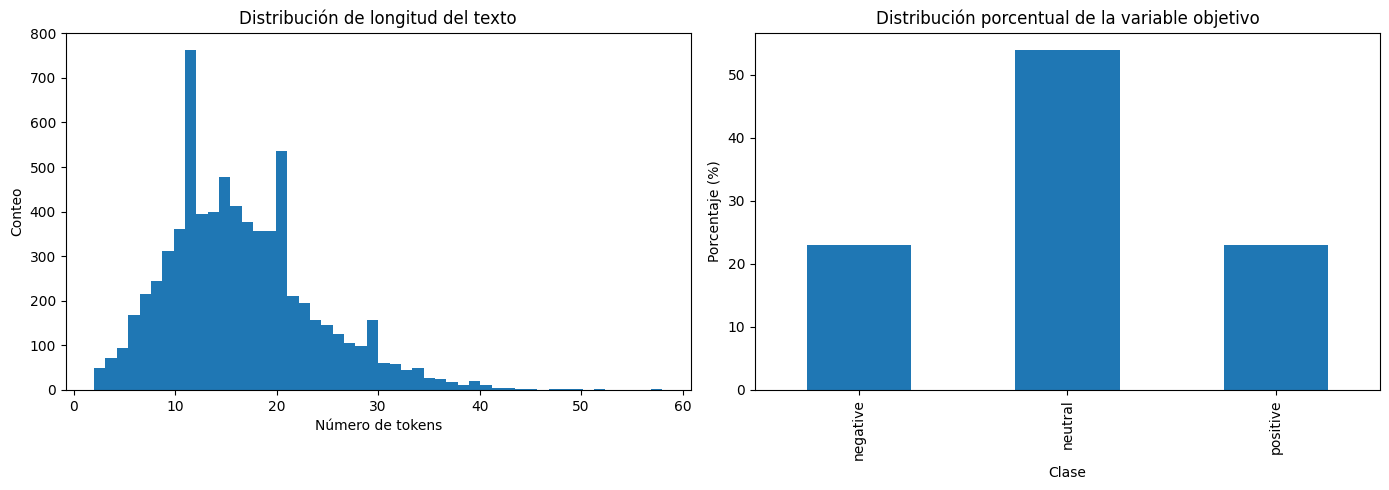

Número de textos: 7,125
Longitud media: 16.50 tokens
Mediana: 16 tokens
Percentil 95: 30 tokens
Vocabulario observado (antes de vectorizar): 13,033 tokens únicos


In [4]:
tamaño_texto = data['sentence_clean'].astype(str).map(lambda x: len(x.split()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(tamaño_texto, bins=50)
axes[0].set_title('Distribución de longitud del texto')
axes[0].set_xlabel('Número de tokens')
axes[0].set_ylabel('Conteo')

(data['label'].value_counts(normalize=True)
 .sort_index()
 .mul(100)
 .plot(kind='bar', ax=axes[1]))
axes[1].set_title('Distribución porcentual de la variable objetivo')
axes[1].set_xlabel('Clase')
axes[1].set_ylabel('Porcentaje (%)')

plt.tight_layout()
plt.show()

print(f'Número de textos: {len(data):,}')
print(f'Longitud media: {tamaño_texto.mean():.2f} tokens')
print(f'Mediana: {tamaño_texto.median():.0f} tokens')
print(f'Percentil 95: {tamaño_texto.quantile(0.95):.0f} tokens')

vocabulario_observado = set(' '.join(data['sentence_clean'].astype(str)).split())
print(f'Vocabulario observado (antes de vectorizar): {len(vocabulario_observado):,} tokens únicos')


Los textos del corpus son relativamente cortos y el conjunto de datos es de tamaño moderado. Esto favorece el uso de representaciones frecuentistas dispersas como **BoW** y, especialmente, **TF-IDF**, porque requieren pocos recursos, son interpretables y suelen funcionar bien en clasificación de textos cortos.

También se evaluarán **Word2Vec** y **Doc2Vec** como contraste semántico. En Word2Vec, una oración se representará mediante el promedio de los vectores de sus palabras. Esta agregación permite obtener un único vector por documento, aunque puede perder información del orden local de las palabras.

<center>
  <img src="https://drive.google.com/uc?export=view&id=1ugyNbNbWFaPeeAV1tecADxfiBf6O4I3l" width="100%" alt="Agregación">
</center>

Para la configuración final de TF-IDF se evaluarán además **bigramas**, ya que expresiones de dos palabras pueden aportar señal en sentimiento financiero que un unigram aislado no captura. La selección definitiva se hará sin consultar el conjunto `test`.


## **2. Implementación del Embedding**
---


A continuación se evaluarán métodos frecuentistas *bag of word* y *TF-IDF* y métodos profundos a nivel de palabra *Word2vec* empleando la estrategia señalada anteriormente. Adicionalmente, probaremos *Doc2vec*, en función de corroborar el comportamiento esperado.


### **2.1. División de los datos en conjuntos de entrenamiento, ajuste y prueba**

Antes de implementar cualquier método de representación es fundamental separar los datos. El vocabulario, los pesos IDF y cualquier selector supervisado se deben aprender **solo con el conjunto de entrenamiento**; de lo contrario se produciría fuga de información y una evaluación optimista.

Se usa un esquema **Hold-out 70/15/15**:

- **train (70%)**: ajuste de vocabulario, embeddings y selección de características.
- **tune (15%)**: validación de decisiones tomadas durante esta fase.
- **test (15%)**: queda reservado para la evaluación final de la fase de modelamiento.

La división se realiza de forma **estratificada** por `label`, para conservar aproximadamente la proporción de clases en las tres particiones.


**Asegúrese de recordar la semilla usada en esta etapa, ya que será necesaria en procesos posteriores para garantizar la evaluación insesgada.**

In [5]:
SEED = 2402

X_train_tune, X_test, y_train_tune, y_test = train_test_split(
    data['sentence_clean'],
    data['label'],
    test_size=0.15,
    random_state=SEED,
    stratify=data['label']
)

X_train, X_tune, y_train, y_tune = train_test_split(
    X_train_tune,
    y_train_tune,
    test_size=0.1765,  # 0.1765 * 0.85 ≈ 0.15 del total
    random_state=SEED,
    stratify=y_train_tune
)

print(f'Número de registros en train: {len(X_train)}')
print(f'Número de registros en tune:  {len(X_tune)}')
print(f'Número de registros en test:  {len(X_test)}')

distribuciones = pd.concat(
    {
        'train': y_train.value_counts(normalize=True).sort_index(),
        'tune': y_tune.value_counts(normalize=True).sort_index(),
        'test': y_test.value_counts(normalize=True).sort_index(),
    },
    axis=1
).mul(100)

display(distribuciones.round(2).rename_axis('label'))


Número de registros en train: 4987
Número de registros en tune:  1069
Número de registros en test:  1069


,train,tune,test
label,,,
negative,23.04,23.01,23.01
neutral,53.92,53.88,53.98
positive,23.04,23.11,23.01


### **2.2. Métodos frecuentistas**

Primero se comparan **Bag of Words (BoW)** y **TF-IDF** bajo una configuración deliberadamente compacta de **512 características**. Mantener la misma dimensionalidad facilita una comparación inicial con las representaciones densas y evita que una técnica obtenga ventaja únicamente por usar más variables.

En ambos casos el vocabulario se aprende exclusivamente con `X_train`. Además:

- `min_df=2` elimina términos que aparecen una sola vez y que suelen aportar ruido.
- `max_df=0.98` descarta términos excesivamente ubicuos.
- En TF-IDF se usa `sublinear_tf=True` para reducir el efecto de repeticiones muy frecuentes dentro de un mismo documento.
- Esta configuración de 512 variables es **comparativa**, no la configuración final. Más adelante se optimizará TF-IDF con bigramas y selección supervisada de características.

**Configuración comparativa:**
- `max_features=512`
- `ngram_range=(1, 1)`
- `min_df=2`
- `max_df=0.98`


#### **2.2.1. Bag of words (BoW)**

In [6]:
BoW_vectorizer = CountVectorizer(
    max_features=512,
    ngram_range=(1, 1),
    min_df=2,
    max_df=0.98,
    dtype=np.int32
)

BoW_vectorizer.fit(X_train)

Bow_train_sparse = BoW_vectorizer.transform(X_train)
Bow_tune_sparse = BoW_vectorizer.transform(X_tune)

# Se densifica únicamente la versión compacta (512 variables) para los análisis
# exploratorios posteriores de correlación/PCA.
Bow_train_embeddings = pd.DataFrame(
    Bow_train_sparse.toarray(),
    columns=BoW_vectorizer.get_feature_names_out()
)
Bow_embeddings = pd.DataFrame(
    Bow_tune_sparse.toarray(),
    columns=BoW_vectorizer.get_feature_names_out()
)

Bow_embeddings.head()


,abril,abrir,acceso,accionista,acción,actividad,activo,activos,actual,acumular,...,viernes,vivienda,volatilidad,volver,wall,web,zona,él,índice,único
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,2,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


#### **2.2.2. Term Frequency-Inverse Document Frequency (TF-IDF)**

In [7]:
TFIDF_vectorizer = TfidfVectorizer(
    max_features=512,
    ngram_range=(1, 1),
    min_df=2,
    max_df=0.98,
    sublinear_tf=True,
    norm='l2',
    dtype=np.float32
)

TFIDF_vectorizer.fit(X_train)

TFIDF_train_sparse = TFIDF_vectorizer.transform(X_train)
TFIDF_tune_sparse = TFIDF_vectorizer.transform(X_tune)

TFIDF_train_embedding = pd.DataFrame(
    TFIDF_train_sparse.toarray(),
    columns=TFIDF_vectorizer.get_feature_names_out()
)
TFIDFembedding = pd.DataFrame(
    TFIDF_tune_sparse.toarray(),
    columns=TFIDF_vectorizer.get_feature_names_out()
)

TFIDFembedding.head()


,abril,abrir,acceso,accionista,acción,actividad,activo,activos,actual,acumular,...,viernes,vivienda,volatilidad,volver,wall,web,zona,él,índice,único
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.295261,0.0,0.000000,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.200637,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0


### **2.3. Métodos densos entrenados sobre el corpus**

A continuación se ajustan *Word2Vec* y *Doc2Vec* como representaciones densas de contraste. Dado que el corpus es moderado, se usa una dimensionalidad de **200** en lugar de 512: esto reduce tiempo y memoria y evita introducir una representación innecesariamente grande para un conjunto de entrenamiento de pocos miles de documentos.

Estas técnicas se entrenan únicamente con `X_train`. Su principal ventaja es capturar relaciones distribucionales entre términos; como contraparte, sus dimensiones no tienen una interpretación directa comparable a las características de TF-IDF.


#### **2.3.1. Word2Vec**

In [8]:
logging.disable(logging.CRITICAL)

# Para un corpus de este tamaño, 200 dimensiones son suficientes como comparación
# y resultan considerablemente más eficientes que 512.
DENSE_DIM = 200

# workers=1 hace reproducible el entrenamiento de gensim al usar una semilla fija.
N_WORKERS = 1

tokens_train = [doc.split() for doc in X_train.astype(str)]

word_model = Word2Vec(
    sentences=tokens_train,
    vector_size=DENSE_DIM,
    window=5,
    min_count=2,
    epochs=20,
    seed=SEED,
    workers=N_WORKERS
)

print(f'Tamaño del vocabulario aprendido: {len(word_model.wv.key_to_index):,} palabras')
print(f'Dimensionalidad Word2Vec: {DENSE_DIM}')


Tamaño del vocabulario aprendido: 5,068 palabras
Dimensionalidad Word2Vec: 200


En Word2Vec se obtiene una representación para cada palabra. Para representar una oración completa se usa el **promedio** de los vectores disponibles en su vocabulario.

El promedio, en lugar de la suma, evita que la magnitud del vector crezca principalmente con la longitud del texto. Los términos fuera del vocabulario se ignoran y, si un documento no contiene ningún término conocido, se devuelve un vector de ceros.


In [9]:
def vector_documento(doc, modelo, dim=DENSE_DIM):
    """Representa un documento como el promedio de sus vectores de palabra."""
    vectores = [
        modelo.wv[token]
        for token in str(doc).split()
        if token in modelo.wv.key_to_index
    ]
    return np.mean(vectores, axis=0) if vectores else np.zeros(dim, dtype=np.float32)

word2vect_train_embedding = pd.DataFrame(
    [vector_documento(doc, word_model) for doc in X_train]
)
word2vect_embedding = pd.DataFrame(
    [vector_documento(doc, word_model) for doc in X_tune]
)

word2vect_embedding.head()


,0,1,2,3,4,5,6,7,8,9,...,190,191,192,193,194,195,196,197,198,199
0,0.036913,0.337302,0.713483,-0.036709,1.060648,-0.131896,-0.264279,0.092205,-0.194849,-1.156060,...,-0.376481,-0.567902,-0.537924,-0.427080,0.454593,-0.159208,-0.223265,-0.501395,0.673035,0.427842
1,0.198599,-0.191480,0.181893,0.161713,0.174707,0.079374,-0.082137,0.405005,-0.067737,-0.148643,...,-0.127667,-0.000422,-0.142818,0.249089,0.282244,0.346505,0.124536,0.030611,-0.126549,-0.107677
2,0.233550,-0.205708,0.111726,0.219508,0.055987,0.175764,-0.061345,0.531276,-0.122906,-0.038870,...,0.022978,0.170176,-0.126768,0.541292,0.246149,0.562412,0.111045,0.036482,-0.123865,-0.064221
3,0.106605,-0.074758,0.248528,0.138826,0.371034,-0.169035,-0.000820,0.121397,-0.017802,-0.300721,...,-0.140619,-0.009809,-0.050223,-0.166179,0.315125,0.265748,0.040805,-0.044642,0.045913,0.026877
4,0.196993,-0.061727,0.159807,0.198631,0.148495,0.170188,-0.171229,0.035579,-0.221516,-0.221605,...,-0.037023,0.016574,-0.197591,0.039933,0.114526,0.122978,0.083336,0.149666,0.042350,-0.055847


#### **2.3.2. Doc2Vec**

In [10]:
logging.disable(logging.CRITICAL)

tokens_train = [doc.split() for doc in X_train.astype(str)]
train_tagged_corpus = [
    TaggedDocument(words=doc, tags=[i])
    for i, doc in enumerate(tokens_train)
]

model_trained = Doc2Vec(
    documents=train_tagged_corpus,
    vector_size=DENSE_DIM,
    window=5,
    min_count=2,
    epochs=20,
    seed=SEED,
    workers=N_WORKERS
)


In [11]:
# Representación del conjunto de entrenamiento: vectores aprendidos directamente.
doc2vect_train_embedding = pd.DataFrame(
    [model_trained.dv[i] for i in range(len(train_tagged_corpus))]
)

# Representación de tune: inferencia sobre documentos nunca usados para entrenar Doc2Vec.
model_trained.random.seed(SEED)
doc2vect_embedding = pd.DataFrame([
    model_trained.infer_vector(str(doc).split(), epochs=20)
    for doc in X_tune
])

doc2vect_embedding.head()


,0,1,2,3,4,5,6,7,8,9,...,190,191,192,193,194,195,196,197,198,199
0,0.028028,-0.016332,0.010545,0.008233,0.032369,0.010957,-0.029591,0.033542,-0.019941,-0.019460,...,-0.005053,0.013490,-0.033460,0.031510,0.013930,0.011532,0.030324,-0.007100,0.006784,0.000250
1,0.097930,-0.040343,0.017671,-0.036888,0.067606,0.059684,-0.090156,0.099389,0.027976,0.009603,...,-0.046143,-0.050269,-0.012623,0.030568,0.015351,0.056428,0.028675,0.065806,-0.087164,0.008834
2,0.144131,0.107274,0.006998,0.025982,0.003142,0.102354,-0.002540,0.075468,-0.042831,-0.003421,...,-0.009900,0.086023,0.015950,0.188140,0.065098,0.138601,-0.105052,-0.045847,-0.019973,0.096782
3,-0.015407,-0.015869,0.013822,0.015582,-0.011362,-0.030370,0.014129,0.034658,0.055874,0.009584,...,-0.065577,-0.025167,0.006098,-0.005799,0.029710,-0.014786,0.034299,-0.045985,0.015317,-0.000509
4,0.035885,-0.041093,0.006830,0.035711,0.062122,0.018722,0.011624,-0.013332,-0.056576,-0.053065,...,-0.036032,-0.047118,0.000120,-0.060677,-0.027058,-0.073187,-0.013760,0.041169,-0.020367,-0.014552


## **3. Exploración y comparación de las representaciones**
---

Una vez ajustadas las representaciones con `train`, se analiza su comportamiento sobre `tune`. Se consideran criterios complementarios:

1. **Redundancia interna:** cuánto contenido repetido existe entre las dimensiones.
2. **Asociación exploratoria con la variable objetivo:** si las características muestran señal relacionada con el sentimiento.
3. **Interpretabilidad:** especialmente relevante para TF-IDF, donde cada dimensión corresponde a un término.
4. **Capacidad discriminante multivariada:** si un clasificador lineal sencillo puede aprovechar la representación.

El análisis de esta sección es comparativo. La **selección supervisada final de características** se realizará posteriormente con estadístico `chi²` usando exclusivamente `train`.


#### **3.1. Redundancia interna**

La redundancia se refiere al fenómeno en el que la mayoría de las características de nuestro conjunto de datos están correlacionadas entre sí. Generalmente ocurre cuando los descriptores extraídos no siguen un patrón regular, lo que hace que su distribución sea aleatoria. Una representación redundante desperdicia dimensiones: aunque tengamos 512 características, la información contenida es mucho menor.

Para validarlo analizaremos los mapas de correlación y, adicionalmente, resumiremos la magnitud de las correlaciones fuera de la diagonal, ya que con 512 características el mapa de calor por sí solo no permite cuantificar el fenómeno.

label
neutral     576
positive    247
negative    246
Name: count, dtype: int64
Registros en tune: 1069 | nulos tras codificar: 0


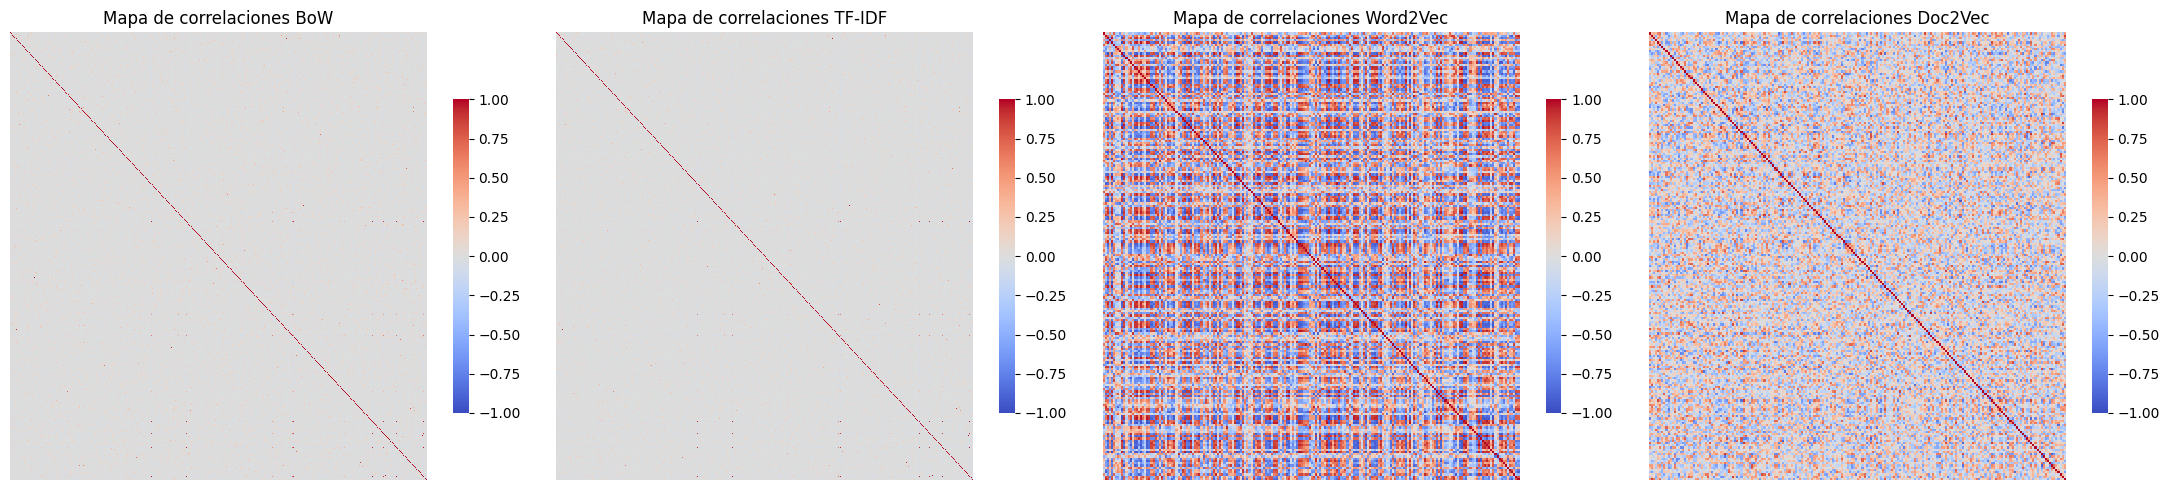

,n_caracteristicas,|r| medio,|r| percentil 95,|r| maximo,% pares |r| > 0.8
BoW,512.0,0.0213,0.0809,1.0000,0.0206
TF-IDF,512.0,0.0188,0.0657,1.0000,0.0199
Word2Vec,200.0,0.4999,0.8974,0.9886,15.0402
Doc2Vec,200.0,0.2824,0.6322,0.9307,0.3869


In [12]:
# Representaciones de train y tune
embeddings_train = {
    'BoW':      Bow_train_embeddings,
    'TF-IDF':   TFIDF_train_embedding,
    'Word2Vec': word2vect_train_embedding,
    'Doc2Vec':  doc2vect_train_embedding,
}

embeddings = {
    'BoW':      Bow_embeddings,
    'TF-IDF':   TFIDFembedding,
    'Word2Vec': word2vect_embedding,
    'Doc2Vec':  doc2vect_embedding,
}

# Codificación ordinal usada únicamente para una lectura exploratoria de signo/magnitud.
# La selección final no dependerá de Pearson: se hará con chi² sobre train.
orden_label = {'negative': 0, 'neutral': 1, 'positive': 2}
y_tune_num = y_tune.map(orden_label).astype(float).reset_index(drop=True)
y_tune_cat = y_tune.reset_index(drop=True)
y_train_cat = y_train.reset_index(drop=True)

print(y_tune_cat.value_counts())
print(f'Registros en tune: {len(y_tune_num)} | nulos tras codificar: {y_tune_num.isna().sum()}')

def matriz_correlacion(df):
    """Correlación de Pearson descartando características constantes."""
    df_valido = df.loc[:, df.std(numeric_only=True) > 0]
    return df_valido.corr()

def resumen_redundancia(corr):
    """Estadísticos de correlaciones absolutas fuera de la diagonal."""
    valores = corr.abs().values
    iu = np.triu_indices_from(valores, k=1)
    fuera_diagonal = valores[iu]
    fuera_diagonal = fuera_diagonal[~np.isnan(fuera_diagonal)]

    if len(fuera_diagonal) == 0:
        return pd.Series({
            'n_caracteristicas': corr.shape[1],
            '|r| medio': np.nan,
            '|r| percentil 95': np.nan,
            '|r| maximo': np.nan,
            '% pares |r| > 0.8': np.nan,
        })

    return pd.Series({
        'n_caracteristicas': corr.shape[1],
        '|r| medio': fuera_diagonal.mean(),
        '|r| percentil 95': np.percentile(fuera_diagonal, 95),
        '|r| maximo': fuera_diagonal.max(),
        '% pares |r| > 0.8': (fuera_diagonal > 0.8).mean() * 100,
    })

matrices = {nombre: matriz_correlacion(df) for nombre, df in embeddings.items()}

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, (nombre, corr) in zip(axes, matrices.items()):
    sns.heatmap(
        corr,
        cmap='coolwarm',
        vmin=-1,
        vmax=1,
        ax=ax,
        xticklabels=False,
        yticklabels=False,
        cbar_kws={'shrink': 0.7}
    )
    ax.set_title(f'Mapa de correlaciones {nombre}')

plt.tight_layout()
plt.show()

tabla_redundancia = pd.DataFrame({
    n: resumen_redundancia(m) for n, m in matrices.items()
}).T

tabla_redundancia.round(4)


**Interpretación.** En esta comparación interesa observar si una representación utiliza sus dimensiones de forma complementaria o si muchas variables contienen información muy parecida. BoW y TF-IDF suelen producir matrices dispersas y altamente interpretables, mientras que los embeddings densos pueden presentar mayor correlación entre dimensiones.

No se decide el método únicamente a partir de la correlación interna: una representación puede ser poco redundante y, aun así, no contener suficiente señal para la tarea. Por eso este resultado se combina con la asociación con `label`, la interpretabilidad y una verificación multivariada.


#### **3.2. Relación con la variable objetivo**

Una representación no redundante no implica necesariamente que esté asociada con la variable objetivo. Como diagnóstico exploratorio se analiza la correlación entre cada dimensión y una codificación ordinal del sentimiento (`negative` < `neutral` < `positive`).

Este análisis permite inspeccionar **dirección y magnitud** de asociaciones en términos interpretables de TF-IDF, pero no se utilizará como criterio supervisado definitivo porque `label` es una variable categórica multiclase. La selección final de características se realizará con **chi-cuadrado (`chi²`)**, una prueba adecuada para características TF-IDF no negativas y clases categóricas.


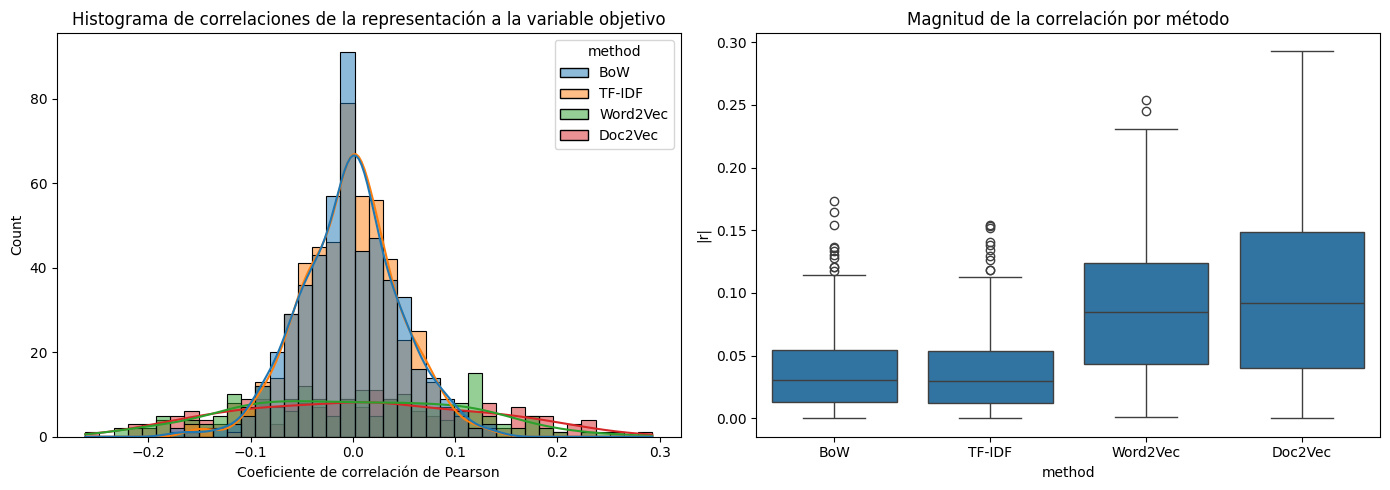

,metodo,n_caracteristicas,|r| medio,|r| percentil 95,|r| maximo,% con |r| > 0.1
0,BoW,512,0.0366,0.0954,0.1733,4.1016
1,TF-IDF,512,0.0361,0.0923,0.1546,3.7109
2,Word2Vec,200,0.0895,0.1975,0.2541,41.0000
3,Doc2Vec,200,0.0969,0.2128,0.2928,45.0000


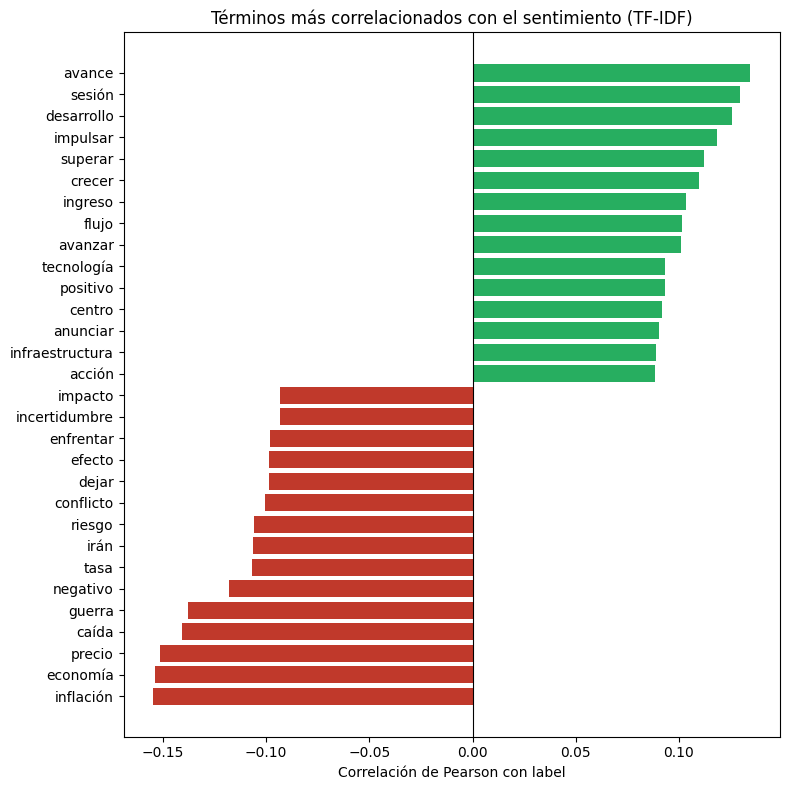

In [13]:
resumen, distribuciones = [], []

for nombre, df in embeddings.items():
    df_valido = df.loc[:, df.std(numeric_only=True) > 0].reset_index(drop=True)
    corr_obj = df_valido.corrwith(y_tune_num).dropna()

    distribuciones.append(pd.DataFrame({'value': corr_obj.values, 'method': nombre}))
    resumen.append({
        'metodo':            nombre,
        'n_caracteristicas': len(corr_obj),
        '|r| medio':         corr_obj.abs().mean(),
        '|r| percentil 95':  np.percentile(corr_obj.abs(), 95),
        '|r| maximo':        corr_obj.abs().max(),
        '% con |r| > 0.1':   (corr_obj.abs() > 0.1).mean() * 100,
    })

obj_corr = pd.concat(distribuciones, ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=obj_corr, x='value', hue='method', kde=True, bins=40, ax=axes[0])
axes[0].set_title('Histograma de correlaciones de la representación a la variable objetivo')
axes[0].set_xlabel('Coeficiente de correlación de Pearson')

sns.boxplot(data=obj_corr.assign(abs_value=obj_corr['value'].abs()),
            x='method', y='abs_value', ax=axes[1])
axes[1].set_title('Magnitud de la correlación por método')
axes[1].set_ylabel('|r|')

plt.tight_layout()
plt.show()

display(pd.DataFrame(resumen).round(4))

# Términos más asociados al sentimiento (solo interpretable en representaciones frecuentistas)
corr_tfidf = (TFIDFembedding.loc[:, TFIDFembedding.std() > 0]
              .reset_index(drop=True)
              .corrwith(y_tune_num)
              .dropna()
              .sort_values())

top_terminos = pd.concat([corr_tfidf.head(15), corr_tfidf.tail(15)])

plt.figure(figsize=(8, 8))
colores = ['#c0392b' if v < 0 else '#27ae60' for v in top_terminos.values]
plt.barh(top_terminos.index, top_terminos.values, color=colores)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Términos más correlacionados con el sentimiento (TF-IDF)')
plt.xlabel('Correlación de Pearson con label')
plt.tight_layout()
plt.show()

La señal de sentimiento en PLN suele estar distribuida entre múltiples términos y no concentrada en una sola característica. Por ello, correlaciones marginales moderadas no implican que la representación sea débil.

En TF-IDF, el gráfico de términos permite verificar cualitativamente que las características con mayor asociación corresponden a vocabulario económico y no a artefactos del preprocesamiento. Esta interpretabilidad constituye una ventaja importante frente a Word2Vec y Doc2Vec, cuyas dimensiones no se pueden mapear directamente a palabras concretas.

La comparación multivariada de la siguiente sección permite comprobar si esa señal distribuida puede ser aprovechada por un clasificador lineal sencillo.


#### **3.3. Nubes de palabras por clase**

Para complementar el análisis anterior con una visualización directa de la representación, construimos nubes de palabras a partir de los **pesos TF-IDF acumulados por clase** (no de conteos crudos), de modo que reflejen exactamente la representación que estamos evaluando.

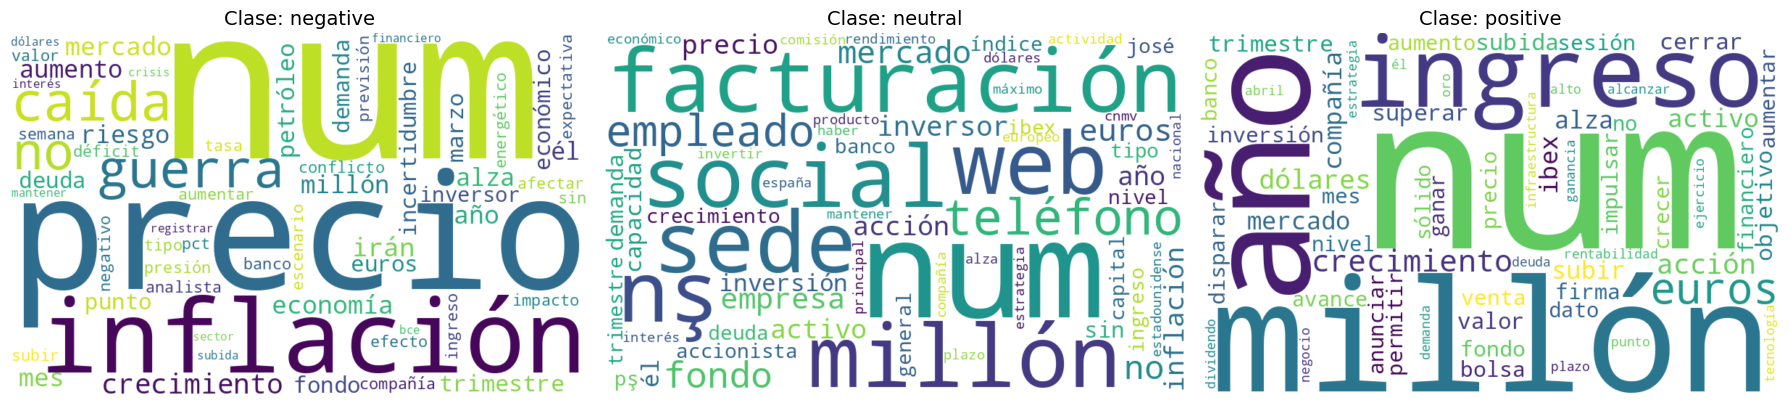

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, clase in zip(axes, ['negative', 'neutral', 'positive']):
    indices = y_tune_cat[y_tune_cat == clase].index
    pesos = TFIDFembedding.loc[indices].sum().sort_values(ascending=False).head(60)

    nube = WordCloud(width=800, height=500, background_color='white',
                     colormap='viridis').generate_from_frequencies(pesos.to_dict())

    ax.imshow(nube, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(f'Clase: {clase}', fontsize=14)

plt.tight_layout()
plt.show()

#### **3.4. Estructura y capacidad discriminante multivariada**

Las correlaciones anteriores son **marginales**: miden una característica a la vez. Para complementar el análisis se usan dos herramientas:

- Una proyección a **dos componentes principales (PCA)** para visualizar la estructura global de cada representación.
- Un **clasificador lineal base** entrenado con `train` y evaluado una sola vez en `tune`. Este modelo no representa la fase final de modelamiento; funciona únicamente como una prueba de que la representación contiene señal útil.

A diferencia de una validación cruzada realizada sobre `tune`, este esquema conserva la función de `tune` como conjunto de validación y evita utilizarlo para ajustar los parámetros del clasificador.


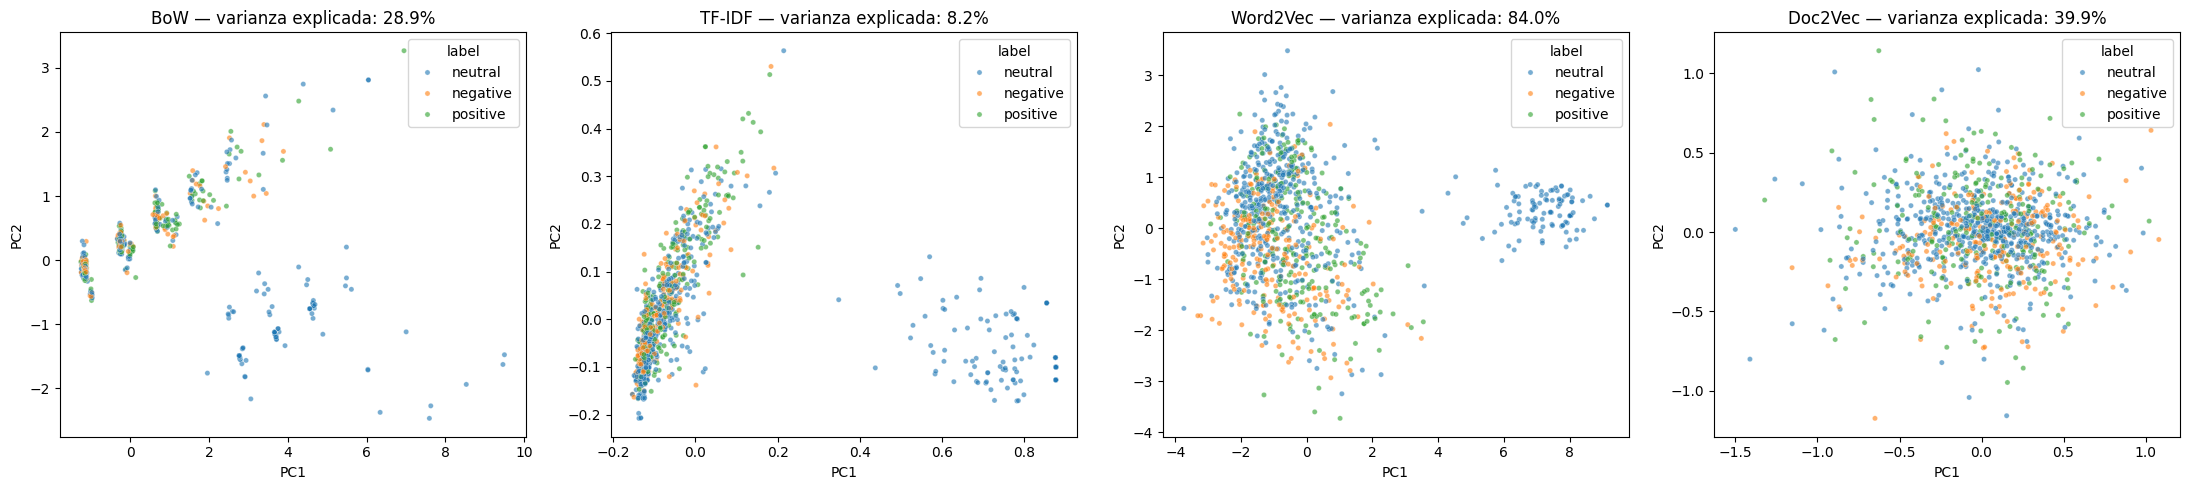

Regresión logística — train → tune



,representacion,n_features,F1_macro_tune,tiempo_fit_s
0,TF-IDF,512,0.6104,1.2423
1,Word2Vec,200,0.5979,9.1429
2,BoW,512,0.5924,1.4752
3,Doc2Vec,200,0.5378,4.9473


In [15]:
# a) Proyección a 2 componentes principales sobre tune
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

for ax, (nombre, df) in zip(axes, embeddings.items()):
    pca = PCA(n_components=2, random_state=SEED).fit(df.values)
    componentes = pca.transform(df.values)

    sns.scatterplot(
        x=componentes[:, 0],
        y=componentes[:, 1],
        hue=y_tune_cat,
        s=14,
        alpha=0.6,
        ax=ax
    )
    ax.set_title(
        f'{nombre} — varianza explicada: '
        f'{pca.explained_variance_ratio_.sum():.1%}'
    )
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')

plt.tight_layout()
plt.show()

# b) Modelo base: entrenar en train y validar en tune
print('Regresión logística — train → tune\n')
resultados_base = []

for nombre in embeddings:
    Xtr = embeddings_train[nombre].values
    Xva = embeddings[nombre].values

    modelo = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            class_weight='balanced',
            random_state=SEED
        )
    )

    inicio = time.perf_counter()
    modelo.fit(Xtr, y_train_cat)
    tiempo_fit = time.perf_counter() - inicio

    pred = modelo.predict(Xva)
    f1 = f1_score(y_tune_cat, pred, average='macro')

    resultados_base.append({
        'representacion': nombre,
        'n_features': Xtr.shape[1],
        'F1_macro_tune': f1,
        'tiempo_fit_s': tiempo_fit,
    })

display(
    pd.DataFrame(resultados_base)
      .sort_values('F1_macro_tune', ascending=False)
      .reset_index(drop=True)
      .round(4)
)


#### **3.5. Conclusión de la comparación inicial**

La comparación inicial permite mantener **TF-IDF como representación principal** para la siguiente etapa por cuatro razones:

1. **Adecuación al problema:** los documentos son cortos y el corpus es moderado, condiciones favorables para una representación dispersa basada en términos.
2. **Interpretabilidad:** cada dimensión puede relacionarse con una palabra o expresión concreta, algo valioso en análisis de sentimiento financiero.
3. **Eficiencia:** el cálculo de TF-IDF es ligero y produce matrices dispersas; no requiere entrenar un modelo neuronal adicional.
4. **Capacidad discriminante:** la verificación con un clasificador lineal permite contrastar su utilidad frente a BoW, Word2Vec y Doc2Vec sin utilizar el conjunto `test`.

La comparación de 512 dimensiones no se toma como configuración definitiva. Para cumplir de forma explícita con la **selección eficiente de características**, la siguiente sección amplía el vocabulario de TF-IDF con unigramas y bigramas y después aplica una selección `chi²` ajustada únicamente con `train`.


## **4. Selección final y eficiente de características**
---

Esta sección materializa directamente el criterio de la rúbrica: no basta con extraer características correctamente; la representación seleccionada debe ser **eficiente y adecuada al problema**.

Se parte de TF-IDF y se incorpora:

- **Unigramas y bigramas (`ngram_range=(1, 2)`)** para capturar palabras individuales y expresiones locales.
- `min_df=2` para filtrar términos extremadamente raros.
- `max_df=0.95` para eliminar términos demasiado frecuentes.
- `sublinear_tf=True` para atenuar repeticiones dentro de un mismo documento.
- `dtype=np.float32` y conservación del formato **sparse** para reducir memoria.
- **Selección supervisada `SelectKBest(chi2)`**, apropiada porque TF-IDF produce valores no negativos y `label` es categórica.

El número de características `k` se elige mediante validación cruzada **exclusivamente dentro de `train`**. El conjunto `test` permanece intacto.


In [16]:
# 4.1. TF-IDF candidato: vocabulario más rico, manteniendo representación sparse
tfidf_final = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    max_features=5000,
    sublinear_tf=True,
    norm='l2',
    dtype=np.float32
)

X_train_tfidf_full = tfidf_final.fit_transform(X_train)
X_tune_tfidf_full = tfidf_final.transform(X_tune)
X_test_tfidf_full = tfidf_final.transform(X_test)  # solo transformación; NO se usa y_test

feature_names_full = tfidf_final.get_feature_names_out()

print(f'Forma train TF-IDF completo: {X_train_tfidf_full.shape}')
print(f'Forma tune TF-IDF completo:  {X_tune_tfidf_full.shape}')
print(f'Características candidatas:  {len(feature_names_full):,}')


Forma train TF-IDF completo: (4987, 5000)
Forma tune TF-IDF completo:  (1069, 5000)
Características candidatas:  5,000


### **4.2. Selección de `k` sin fuga de información**

Para escoger cuántas características conservar se usa un `Pipeline` con:

1. TF-IDF.
2. `SelectKBest(chi2)`.
3. Regresión logística únicamente como **modelo auxiliar de validación**.

La búsqueda de `k` se realiza con `StratifiedKFold` sobre `train`. De esta manera, tanto el vocabulario como el IDF y el selector `chi²` se vuelven a ajustar dentro de cada fold, evitando que la partición de validación interna influya en la extracción de características.


In [17]:
# Valores candidatos adaptados al número real de características disponibles
n_features_full = X_train_tfidf_full.shape[1]
candidate_k = sorted({
    min(k, n_features_full)
    for k in (256, 512, 1024, 2048)
})

cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=SEED
)

pipeline_seleccion = Pipeline([
    ('tfidf', TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        max_features=5000,
        sublinear_tf=True,
        norm='l2',
        dtype=np.float32
    )),
    ('select', SelectKBest(score_func=chi2)),
    ('clf', LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=SEED
    ))
])

busqueda_k = GridSearchCV(
    estimator=pipeline_seleccion,
    param_grid={'select__k': candidate_k},
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    return_train_score=False
)

busqueda_k.fit(X_train, y_train)

resultados_k = pd.DataFrame(busqueda_k.cv_results_)[[
    'param_select__k',
    'mean_test_score',
    'std_test_score',
    'mean_fit_time'
]].rename(columns={
    'param_select__k': 'k',
    'mean_test_score': 'F1_macro_CV',
    'std_test_score': 'std_CV',
    'mean_fit_time': 'tiempo_fit_s'
}).sort_values('F1_macro_CV', ascending=False)

best_k = int(busqueda_k.best_params_['select__k'])

display(resultados_k.round(4))
print(f'k seleccionado usando solo train: {best_k}')


,k,F1_macro_CV,std_CV,tiempo_fit_s
3,2048,0.6509,0.0113,0.6363
2,1024,0.6458,0.0169,0.5824
1,512,0.6308,0.0164,0.5386
0,256,0.6111,0.0145,0.5892


k seleccionado usando solo train: 2048


### **4.3. Ajuste del selector final y características retenidas**

Una vez fijado `k`, el selector se ajusta sobre todo el conjunto `train`. Después se aplica exactamente la misma transformación a `tune` y `test`. Esto deja preparada la matriz de características para la siguiente fase sin volver a consultar las etiquetas de `tune` ni de `test`.


In [18]:
selector_final = SelectKBest(score_func=chi2, k=best_k)

X_train_final = selector_final.fit_transform(X_train_tfidf_full, y_train)
X_tune_final = selector_final.transform(X_tune_tfidf_full)
X_test_final = selector_final.transform(X_test_tfidf_full)

selected_idx = selector_final.get_support(indices=True)
selected_feature_names = feature_names_full[selected_idx]

print(f'Características antes de seleccionar: {X_train_tfidf_full.shape[1]:,}')
print(f'Características seleccionadas:        {X_train_final.shape[1]:,}')
print(
    f'Reducción dimensional: '
    f'{100 * (1 - X_train_final.shape[1] / X_train_tfidf_full.shape[1]):.2f}%'
)

# Características con mayor asociación chi² dentro de las seleccionadas
scores_seleccionados = selector_final.scores_[selected_idx]
top_idx_local = np.argsort(scores_seleccionados)[-30:][::-1]

top_features_chi2 = pd.DataFrame({
    'feature': selected_feature_names[top_idx_local],
    'chi2': scores_seleccionados[top_idx_local]
})

display(top_features_chi2.round(4))


Características antes de seleccionar: 5,000
Características seleccionadas:        2,048
Reducción dimensional: 59.04%


,feature,chi2
0,web,69.9216
1,sede social,69.0014
2,sede,68.2984
3,teléfono,68.1578
4,teléfono web,66.7356
5,facturación num,65.9721
6,nş,65.7866
7,num teléfono,65.4987
8,nş empleado,64.3142
9,web facturación,63.7459


### **4.4. Evidencia de eficiencia**

Para cuantificar la eficiencia se compara la representación TF-IDF completa con la representación seleccionada. Se reportan dimensionalidad, densidad y memoria real de la matriz dispersa. Así se evita afirmar eficiencia únicamente de forma cualitativa.


In [19]:
def sparse_memory_mb(X):
    """Memoria real aproximada de una matriz CSR/CSC en MB."""
    return (X.data.nbytes + X.indices.nbytes + X.indptr.nbytes) / (1024 ** 2)

def sparse_density(X):
    return X.nnz / (X.shape[0] * X.shape[1])

tabla_eficiencia = pd.DataFrame([
    {
        'representacion': 'TF-IDF completo',
        'n_features': X_train_tfidf_full.shape[1],
        'nnz': X_train_tfidf_full.nnz,
        'densidad_%': sparse_density(X_train_tfidf_full) * 100,
        'memoria_MB': sparse_memory_mb(X_train_tfidf_full),
    },
    {
        'representacion': 'TF-IDF + chi2',
        'n_features': X_train_final.shape[1],
        'nnz': X_train_final.nnz,
        'densidad_%': sparse_density(X_train_final) * 100,
        'memoria_MB': sparse_memory_mb(X_train_final),
    }
])

display(tabla_eficiencia.round(4))


,representacion,n_features,nnz,densidad_%,memoria_MB
0,TF-IDF completo,5000,84211,0.3377,0.6615
1,TF-IDF + chi2,2048,53139,0.5203,0.4244


### **4.5. Verificación de que la reducción conserva señal útil**

El criterio principal de esta fase es la extracción/selección de características, no el entrenamiento del modelo final. Aun así, se utiliza una regresión logística sencilla como control: se compara el TF-IDF completo con el TF-IDF seleccionado y se mide `F1-macro` en `tune`.

`F1-macro` es apropiado porque asigna el mismo peso a cada clase y evita que la clase más frecuente domine la evaluación.


In [20]:
comparacion_final = []

for nombre, Xtr, Xva in [
    ('TF-IDF completo', X_train_tfidf_full, X_tune_tfidf_full),
    ('TF-IDF + chi2', X_train_final, X_tune_final),
]:
    clf = LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=SEED
    )

    inicio = time.perf_counter()
    clf.fit(Xtr, y_train)
    tiempo_fit = time.perf_counter() - inicio

    inicio = time.perf_counter()
    pred = clf.predict(Xva)
    tiempo_pred = time.perf_counter() - inicio

    comparacion_final.append({
        'representacion': nombre,
        'n_features': Xtr.shape[1],
        'F1_macro_tune': f1_score(y_tune, pred, average='macro'),
        'tiempo_fit_s': tiempo_fit,
        'tiempo_pred_s': tiempo_pred,
    })

display(pd.DataFrame(comparacion_final).round(4))


,representacion,n_features,F1_macro_tune,tiempo_fit_s,tiempo_pred_s
0,TF-IDF completo,5000,0.6726,0.6111,0.0008
1,TF-IDF + chi2,2048,0.6627,0.1453,0.0008


### **4.6. Características representativas por clase**

Además del ranking global `chi²`, se inspeccionan los términos con mayor peso TF-IDF medio en cada clase dentro de `train`. Esta revisión cualitativa ayuda a verificar que la representación final conserva vocabulario coherente con el dominio financiero.


In [21]:
# Promedios por clase únicamente sobre train
y_train_arr = y_train.reset_index(drop=True).to_numpy()

rows = []
for clase in sorted(np.unique(y_train_arr)):
    mask = y_train_arr == clase
    media_clase = np.asarray(X_train_final[mask].mean(axis=0)).ravel()
    top_local = np.argsort(media_clase)[-12:][::-1]

    for rank, j in enumerate(top_local, start=1):
        rows.append({
            'clase': clase,
            'rank': rank,
            'feature': selected_feature_names[j],
            'peso_tfidf_medio': media_clase[j],
        })

top_por_clase = pd.DataFrame(rows)
display(top_por_clase.round(5))


,clase,rank,feature,peso_tfidf_medio
0,negative,1,num,0.04945
1,negative,2,caída,0.02659
2,negative,3,inflación,0.02266
3,negative,4,precio,0.02046
4,negative,5,no,0.01903
5,negative,6,año,0.01848
6,negative,7,guerra,0.01777
7,negative,8,mes,0.01626
8,negative,9,deuda,0.01389
9,negative,10,crecimiento,0.01381


### **4.7. Selección final para la fase de modelamiento**

La representación final queda definida por el objeto `tfidf_final` seguido de `selector_final`.

Las matrices que deben reutilizarse en la siguiente fase son:

- `X_train_final`
- `X_tune_final`
- `X_test_final`

y el vector `selected_feature_names` conserva el nombre de cada característica seleccionada.

**Decisión:** se adopta **TF-IDF de unigramas + bigramas con filtrado de frecuencia y selección `chi²`** porque combina señal léxica apropiada para noticias económicas, interpretabilidad y una reducción explícita del costo dimensional. El valor de `k` no se fija arbitrariamente: se determina mediante validación cruzada estratificada dentro de `train`.

El conjunto `test` continúa reservado; sus etiquetas (`y_test`) no se han utilizado para elegir representación, hiperparámetros ni características.


## **Referencias:**


---



[1] Kenpache. *Multilingual Financial Sentiment* (dataset). Hugging Face. https://huggingface.co/datasets/Kenpache/multilingual-financial-sentiment

[2] Explosion AI. *spaCy: Industrial-strength Natural Language Processing*. https://spacy.io/

[3] spacy-langdetect. https://github.com/Abhijit-2592/spacy-langdetect

[4] Textstat: índice de legibilidad de Fernández-Huerta. https://www.spanishreadability.com/fernandez-huerta-readability-index

[5] Coeficiente de correlación de Spearman. https://www.sciencedirect.com/topics/mathematics/spearman-rank-correlation-coefficient

[6] V de Cramér (asociación entre variables categóricas). https://en.wikipedia.org/wiki/Cram%C3%A9r%27s_V

[7] Correlación de Pearson. https://www.sciencedirect.com/topics/computer-science/pearson-correlation

[8] scikit-learn. *TfidfVectorizer*. https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html

[9] scikit-learn. *chi2 — Chi-squared stats of non-negative features for classification tasks*. https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.chi2.html


## **Créditos**

* **Profesores:** [Felipe Restrepo Calle](https://ferestrepoca.github.io/), [Elizabeth León Guzman](https://midas.unal.edu.co)
* **Asistentes docentes:**
    - [Juan Sebastián Malagón Torres](https://co.linkedin.com/in/juan-sebastian-malag%C3%B3n-torres-86039a164).
* **Diseño de imágenes:**
    - [Sebastián Daniel Moreno Martinez](http://www.linkedin.com/in/sm-xwx).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).

**Universidad Nacional de Colombia** - *Facultad de Ingeniería*